# Esperienza 4 

## Plot grafici senza correzioni

In [290]:
import ROOT
import numpy as np
import pandas as pd
from scipy.stats import f as f_dist
 
ROOT.gStyle.SetOptFit(1111)    # aggiunge il label con chi2/ndf e probabilita e parametri se metti 0000 toglie i dati
ROOT.gStyle.SetFitFormat(
    "4.2e"
)  # con 2 cifre decimali


#fit 
def Malus(x, par):
    t = x[0]
    A = par[0]
    B = par[1]
    C = par[2]
    return A*np.cos(t - C)**2 + B

def Malus_fondo(x, par):
    t = x[0]
    A = par[0]
    B = par[1]
    C = par[2]
    D = par[3]
    return (A*np.cos(t - C)**2 + B)*(1 + D*t) 

def modellopy(t, A, B, C):         
    return A*np.cos(t - C)**2 + B

def modellopy_fondo(t, A, B, C, D):         
    return (A*np.cos(t - C)**2 + B)* (1+ D*t )

def Malus_deriv(x, par):
    t = x
    dt = 1e-6
    return ((modellopy(t+dt/2, par[0], par[1], par[2])-modellopy(t-dt/2, par[0], par[1], par[2]))/dt)

def Malus_deriv_fondo(x, par):
    t = x
    dt = 1e-6
    return ((modellopy_fondo(t+dt/2, par[0], par[1], par[2], par[3])-modellopy_fondo(t-dt/2, par[0], par[1], par[2], par[3]))/dt)   


xlsx ="Esperienza4.xlsx"
df = pd.read_excel(xlsx, sheet_name= "Dati")
df = df.dropna(subset=["θ [rad]", "V", "sigma_θ", "sigma_V"])
df = df.to_numpy(dtype = 'float64')

x = df[:, 1]     
y = df[:, 2]     

err_x = df[:, 3]     
err_y = df[:, 4]   

# eliminazione primi dati
index = [i for i in range(6)]

x = np.delete(x, index)
y = np.delete(y, index)
err_x = np.delete(err_x, index)
err_y = np.delete(err_y, index)


#minimizzazzione con ROOT
MalusFit = ROOT.TF1('model', Malus, min(x), max(x), 3)
MalusFit.SetParameters(y.max() - y.min(), y.min(), x[np.argmax(y)])     # A è Vmax-Vmin, B è Vmin, C è posizione del massimo
MalusFit.SetParNames("A", "B", "C")

gr1 = ROOT.TGraphErrors(len(x), x, y, err_x, err_y)
gr1.SetTitle("Dati sperimentali e fit; #theta [rad]; V [V]")
gr1.SetMarkerStyle(20)
gr1.SetMarkerSize(0.7)                    
gr1.SetMarkerColor(ROOT.kAzure + 2)
gr1.SetLineColor(ROOT.kAzure + 3)        
gr1.SetLineWidth(1)


fit_res = gr1.Fit(MalusFit, "S") # SR significa che voglio fare il fit senza disegnare la funzione e senza stampare a video i risultati del fit 

fitStatus = fit_res.Status()
print(f"Fit status: {fitStatus}")

par = MalusFit.GetParameters()

errors = MalusFit.GetParErrors()

chi2 = fit_res.Chi2()
ndf = fit_res.Ndf()

err_yeff = np.sqrt(err_y**2 + ((Malus_deriv(x, par)) * err_x)**2) #errore effettivo

print("Parametri stimati:")
print(f"A = {par[0]} ± {errors[0]}")
print(f"B = {par[1]} ± {errors[1]}")
print(f"C = {par[2]} ± {errors[2]}")
print(f"Chi2 = {chi2}, ndf = {ndf}")

c1 = ROOT.TCanvas("c1", "Fit con ROOT", 800, 600)
c1.SetGrid()

gr1.Draw("AP")


leg1 = ROOT.TLegend(0.14, 0.14, 0.42, 0.23)
leg1.AddEntry(gr1, "Dati", "pe")
leg1.AddEntry(MalusFit, "Fit", "l")
leg1.Draw()

c1.Draw()
c1.SaveAs("Immagini/malus_fit.png")


Fit status: 0
Parametri stimati:
A = 1.9738177337719631 ± 0.0029229464372117963
B = 2.7882156780202383 ± 0.0019346300686227124
C = 3.121612612132441 ± 0.0010203025820560803
Chi2 = 751.6519440291628, ndf = 191
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      751.652
NDf                       =          191
Edm                       =  2.07951e-06
NCalls                    =           66
A                         =      1.97382   +/-   0.00292295  
B                         =      2.78822   +/-   0.00193463  
C                         =      3.12161   +/-   0.0010203   


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: png file Immagini/malus_fit.png has been created


In [291]:
if np.abs(par[2]) < 3*errors[2]:
        print("C è compatibile con 0")
else :
        print("C NON è compatibile con 0")

print("---")

if np.abs(par[1]) < 3*errors[1]:
    print("B è compatibile con 0")
else :
    print("B NON è compatibile con 0")
 
 


C NON è compatibile con 0
---
B NON è compatibile con 0


In [292]:

y_attesi = np.array([MalusFit.Eval(x_val) for x_val in x])
residuals_norm = (y - y_attesi) / err_yeff


##NUMERO DI BIN DA USARE (FORMULA BRESSAN)
dev_std = np.std(residuals_norm)
delta_bin = 3.5 * dev_std / (len(residuals_norm))**(1/3)
n_bin= (np.max(residuals_norm) - np.min(residuals_norm))/delta_bin
n_bin = int(np.round(n_bin))
print("numero di bin senza code", n_bin)

##NUMERO DI BIN DA USARE SE PRESENTI CODE (FORMULA BRESSAN)
def IQR(dist):
    return np.percentile(dist, 75) - np.percentile(dist, 25)

delta_bin = 2*IQR(residuals_norm)/ (len(residuals_norm))**(1/3)
n_bin= (np.max(residuals_norm) - np.min(residuals_norm))/delta_bin
n_bin = int(np.round(n_bin))
print("numero di bin con code", n_bin)


gaussian_fit = ROOT.TF1('gaussian', 'gaus', min(residuals_norm), max(residuals_norm), 3)
gaussian_fit.SetParNames("const", "mu", "sigma")
gaussian_fit.SetLineColor(ROOT.kRed + 1)
gaussian_fit.SetLineWidth(3)

hist = ROOT.TH1F("hist", "Istogramma dei dati; x; y", 10, min(residuals_norm), max(residuals_norm))
for val in residuals_norm:
    hist.Fill(val)

gaussian_fit.SetParameters(hist.GetMaximum(), hist.GetMean(), hist.GetRMS())
    
hist.SetLineColor(ROOT.kAzure + 3)
hist.SetLineWidth(2)
hist.SetFillColorAlpha(ROOT.kAzure + 1, 0.55)   
hist.GetXaxis().SetTitle("residuo normalizzato")
hist.GetYaxis().SetTitle("conteggi")
hist.SetTitle("Istogramma residui normalizzati")

r = hist.Fit(gaussian_fit, "S")

fitStatus = r.Status()
print(f"Fit status: {fitStatus}")

parameters = gaussian_fit.GetParameters()
errors = gaussian_fit.GetParErrors()

chi2 = gaussian_fit.GetChisquare()

print("Parametri stimati:")
print(f"const = {parameters[0]} ± {errors[0]}")
print(f"#mu = {parameters[1]} ± {errors[1]}")
print(f"#sigma = {parameters[2]} ± {errors[2]}")
print(f"Chi2 = {chi2}")


c2 = ROOT.TCanvas("c2", "Istogramma dei dati", 800, 600)
c2.SetGrid()

hist.Draw()

leg2 = ROOT.TLegend(0, 0.30, 0.15, 0.39)
leg2.AddEntry(hist, "Residui", "f")
leg2.AddEntry(gaussian_fit, "Fit gaussiano", "l")
leg2.Draw()

ROOT.gStyle.SetOptFit(1111)  
c2.Draw()
c2.SaveAs("Immagini/malus_hist.png")


numero di bin senza code 7
numero di bin con code 8
Fit status: 0
Parametri stimati:
const = 28.830292803865003 ± 2.84341100532437
#mu = 0.4404429367784594 ± 0.20304603626087475
#sigma = 2.2698096680804594 ± 0.2020779690748269
Chi2 = 11.654820557205992
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      11.6548
NDf                       =            7
Edm                       =  9.71172e-06
NCalls                    =           62
const                     =      28.8303   +/-   2.84341     
mu                        =     0.440443   +/-   0.203046    
sigma                     =      2.26981   +/-   0.202078     	 (limited)


Warning in <TROOT::Append>: Replacing existing TH1: hist (Potential memory leak).
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c2
Info in <TCanvas::Print>: png file Immagini/malus_hist.png has been created


In [293]:
if np.abs(parameters[0] - 1) < 3*errors[0]:
    print("const è compatibile con 1")
else :
    print("const NON è compatibile con 1")

print("---")

if np.abs(parameters[1]) < 3*errors[1]:
    print("mu è compatibile con 0")
else :
    print("mu NON è compatibile con 0")

print("---")
if np.abs(parameters[2] - 1) < 3*errors[2]:
    print("sigma è compatibile con 1")
else :
    print("sigma NON è compatibile con 1")

const NON è compatibile con 1
---
mu è compatibile con 0
---
sigma NON è compatibile con 1


In [294]:
def line(x, par):
    x = x[0]
    m = par[0]
    q = par[1]
    return m * x + q

residuals = y - y_attesi

line_fit = ROOT.TF1('line', line, min(x), max(x), 2)
line_fit.SetParameters(1, 0)
line_fit.SetParNames("m", "q")
line_fit.SetLineColor(ROOT.kRed + 1)
line_fit.SetLineWidth(2)

gr2 = ROOT.TGraphErrors(len(x), x, residuals, np.zeros_like(residuals), err_yeff)
gr2.SetTitle("Residui in funzione di #theta; #theta [rad]; V - V_{att} [V]")
gr2.SetMarkerStyle(20)
gr2.SetMarkerSize(0.7)
gr2.SetMarkerColor(ROOT.kAzure + 2)
gr2.SetLineColor(ROOT.kAzure + 3)

fit_res = gr2.Fit(line_fit, "S")

fitStatus = fit_res.Status()
print(f"Fit status: {fitStatus}")

parameters = line_fit.GetParameters()
errors = line_fit.GetParErrors()

chi2 = fit_res.Chi2()

print("Parametri stimati:")
print(f"m = {parameters[0]} ± {errors[0]}")
print(f"q = {parameters[1]} ± {errors[1]}")
print(f"Chi2 = {chi2}")

c3 = ROOT.TCanvas("c3", "Fit con ROOT", 800, 600)
c3.SetGrid()

gr2.Draw("AP")

leg3 = ROOT.TLegend(0.17, 0.80, 0.45, 0.89)
leg3.AddEntry(gr2, "Residui", "pe")
leg3.AddEntry(line_fit, "Fit lineare", "l")
leg3.Draw()

c3.Draw()
c3.SaveAs("Immagini/malus_residui.png")

Fit status: 0
Parametri stimati:
m = -0.005179449721735507 ± 0.0006154110406506038
q = 0.018998134203718875 ± 0.0025471813901903426
Chi2 = 680.8187759027661
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      680.819
NDf                       =          192
Edm                       =  1.60615e-18
NCalls                    =           40
m                         =  -0.00517945   +/-   0.000615411 
q                         =    0.0189981   +/-   0.00254718  


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c3
Info in <TCanvas::Print>: png file Immagini/malus_residui.png has been created


In [295]:
# stima    disfunzionalita polarizzatore
Vmax = MalusFit.GetParameter(0) + MalusFit.GetParameter(1)     # A + B
dV_semi = (residuals.max() - residuals.min())/2

print(f"Vmax = {Vmax:.3f} V")
print(f"DeltaV (semiampiezza) = {dV_semi:.3f} V   ->  DeltaV/Vmax = {dV_semi/Vmax:.3f}")
print(f"DeltaV (picco-picco)  = {2*dV_semi:.3f} V   ->  DeltaV/Vmax = {2*dV_semi/Vmax:.3f}")


Vmax = 4.762 V
DeltaV (semiampiezza) = 0.075 V   ->  DeltaV/Vmax = 0.016
DeltaV (picco-picco)  = 0.150 V   ->  DeltaV/Vmax = 0.032


## Secondo Fit per correggere scarica batteria

In [296]:
#minimizzazzione con ROOT
print(par[0], par[1], par[2])
MalusFit_fondo = ROOT.TF1('model', Malus_fondo, min(x), max(x), 4)
MalusFit_fondo.SetParameters(par[0], par[1], par[2], 0)
MalusFit_fondo.SetParNames("A", "B", "C", "D")

gr1 = ROOT.TGraphErrors(len(x), x, y, err_x, err_y)
gr1.SetTitle("Dati sperimentali e fit; #theta [rad]; V [V]")
gr1.SetMarkerStyle(20)
gr1.SetMarkerSize(0.7)                    
gr1.SetMarkerColor(ROOT.kAzure + 2)
gr1.SetLineColor(ROOT.kAzure + 3)        
gr1.SetLineWidth(1)


fit_res = gr1.Fit(MalusFit_fondo, "SR") # SR significa che voglio fare il fit senza disegnare la funzione e senza stampare a video i risultati del fit 

fitStatus = fit_res.Status()
print(f"Fit status: {fitStatus}")

par_fondo = MalusFit_fondo.GetParameters()

errors_fondo = MalusFit_fondo.GetParErrors()

chi2 = fit_res.Chi2()
ndf = fit_res.Ndf()

err_yeff = np.sqrt(err_y**2 + ((Malus_deriv_fondo(x, par_fondo)) * err_x)**2) #errore effettivo

print("Parametri stimati:")
print(f"A = {par_fondo[0]} ± {errors_fondo[0]}")
print(f"B = {par_fondo[1]} ± {errors_fondo[1]}")
print(f"C = {par_fondo[2]} ± {errors_fondo[2]}")
print(f"D = {par_fondo[3]} ± {errors_fondo[3]}")
print(f"Chi2 = {chi2}, ndf = {ndf}")

c1 = ROOT.TCanvas("c1", "Fit con ROOT", 800, 600)
c1.SetGrid()

gr1.Draw("AP")


leg1 = ROOT.TLegend(0.14, 0.14, 0.42, 0.23)
leg1.AddEntry(gr1, "Dati", "pe")
leg1.AddEntry(MalusFit_fondo, "Fit", "l")
leg1.Draw()

c1.Draw()
c1.SaveAs("Immagini/malus_fit_fondo.png")
ROOT.gStyle.SetOptFit(0000)    

1.9738177337719631 2.7882156780202383 3.121612612132441
Fit status: 0
Parametri stimati:
A = 1.9939602338927584 ± 0.0035871078591666506
B = 2.8009863430425286 ± 0.0023242891930850607
C = 3.1198883362756096 ± 0.0010329323479685354
D = -0.0015974818506622216 ± 0.00015940421500197093
Chi2 = 651.7018449519584, ndf = 190
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      651.702
NDf                       =          190
Edm                       =    1.472e-07
NCalls                    =           99
A                         =      1.99396   +/-   0.00358711  
B                         =      2.80099   +/-   0.00232429  
C                         =      3.11989   +/-   0.00103293  
D                         =  -0.00159748   +/-   0.000159404 


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: png file Immagini/malus_fit_fondo.png has been created


In [297]:
#residui ma per secondo fit

y_attesi_2 = np.array([MalusFit_fondo.Eval(x_val) for x_val in x])
residuals_norm_2 = (y - y_attesi_2) / err_yeff


##NUMERO DI BIN DA USARE (FORMULA BRESSAN)
dev_std = np.std(residuals_norm_2)
delta_bin = 3.5 * dev_std / (len(residuals_norm_2))**(1/3)
n_bin= (np.max(residuals_norm_2) - np.min(residuals_norm_2))/delta_bin
n_bin = int(np.round(n_bin))
print("numero di bin senza code", n_bin)

##NUMERO DI BIN DA USARE SE PRESENTI CODE (FORMULA BRESSAN)
def IQR(dist):
    return np.percentile(dist, 75) - np.percentile(dist, 25)

delta_bin = 2*IQR(residuals_norm_2)/ (len(residuals_norm_2))**(1/3)
n_bin= (np.max(residuals_norm_2) - np.min(residuals_norm_2))/delta_bin
n_bin = int(np.round(n_bin))
print("numero di bin con code", n_bin)


gaussian_fit = ROOT.TF1('gaussian', 'gaus', min(residuals_norm_2), max(residuals_norm_2), 3)
gaussian_fit.SetParNames("const", "mu", "sigma")
gaussian_fit.SetLineColor(ROOT.kRed + 1)
gaussian_fit.SetLineWidth(3)

hist = ROOT.TH1F("hist", "Istogramma dei dati; x; y", 10, min(residuals_norm_2), max(residuals_norm_2))
for val in residuals_norm_2:
    hist.Fill(val)

gaussian_fit.SetParameters(hist.GetMaximum(), hist.GetMean(), hist.GetRMS())
    
hist.SetLineColor(ROOT.kAzure + 3)
hist.SetLineWidth(2)
hist.SetFillColorAlpha(ROOT.kAzure + 1, 0.55)   
hist.GetXaxis().SetTitle("residuo normalizzato")
hist.GetYaxis().SetTitle("conteggi")
hist.SetTitle("Istogramma residui normalizzati secondo fit")

r = hist.Fit(gaussian_fit, "S")

fitStatus = r.Status()
print(f"Fit status: {fitStatus}")

parameters = gaussian_fit.GetParameters()
errors = gaussian_fit.GetParErrors()

chi2 = gaussian_fit.GetChisquare()

print("Parametri stimati:")
print(f"const = {parameters[0]} ± {errors[0]}")
print(f"#mu = {parameters[1]} ± {errors[1]}")
print(f"#sigma = {parameters[2]} ± {errors[2]}")
print(f"Chi2 = {chi2}")


c2 = ROOT.TCanvas("c2", "Istogramma dei dati", 800, 600)
c2.SetGrid()

hist.Draw()

leg2 = ROOT.TLegend(0, 0.30, 0.15, 0.39)
leg2.AddEntry(hist, "Residui", "f")
leg2.AddEntry(gaussian_fit, "Fit gaussiano", "l")
leg2.Draw()

ROOT.gStyle.SetOptFit(1111)  
c2.Draw()
c2.SaveAs("Immagini/malus_hist_fondo.png")

#------------------------------------------------------------
#rettA



def line_2(x, par):
    x = x[0]
    m = par[0]
    q = par[1]
    return m * x + q

residuals_2 = y - y_attesi_2

line_fit = ROOT.TF1('line', line_2, min(x), max(x), 2)
line_fit.SetParameters(1, 0)
line_fit.SetParNames("m", "q")
line_fit.SetLineColor(ROOT.kRed + 1)
line_fit.SetLineWidth(2)

gr2 = ROOT.TGraphErrors(len(x), x, residuals_2, np.zeros_like(residuals_2), err_yeff)
gr2.SetTitle("Residui in funzione di #theta; #theta [rad]; V - V_{att} [V]")
gr2.SetMarkerStyle(20)
gr2.SetMarkerSize(0.7)
gr2.SetMarkerColor(ROOT.kAzure + 2)
gr2.SetLineColor(ROOT.kAzure + 3)

fit_res = gr2.Fit(line_fit, "S")

fitStatus = fit_res.Status()
print(f"Fit status: {fitStatus}")

parameters = line_fit.GetParameters()
errors = line_fit.GetParErrors()

chi2 = fit_res.Chi2()

print("Parametri stimati:")
print(f"m = {parameters[0]} ± {errors[0]}")
print(f"q = {parameters[1]} ± {errors[1]}")
print(f"Chi2 = {chi2}")

c3 = ROOT.TCanvas("c3", "Fit con ROOT", 800, 600)
c3.SetGrid()

gr2.Draw("AP")

leg3 = ROOT.TLegend(0.17, 0.80, 0.45, 0.89)
leg3.AddEntry(gr2, "Residui", "pe")
leg3.AddEntry(line_fit, "Fit lineare", "l")
leg3.Draw()

c3.Draw()
c3.SaveAs("Immagini/malus_residui_fondo.png")



numero di bin senza code 8
numero di bin con code 9
Fit status: 0
Parametri stimati:
const = 34.25590291684502 ± 3.2338988765913728
#mu = 0.40234194467395873 ± 0.14984699874783694
#sigma = 1.720998939620266 ± 0.10283135442117519
Chi2 = 23.65058667934452
Fit status: 0
Parametri stimati:
m = 0.0005345709896654172 ± 0.0006173556707392589
q = -0.0019615316911389957 ± 0.002558056741095062
Chi2 = 650.9520492192906
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      23.6506
NDf                       =            7
Edm                       =  3.59039e-06
NCalls                    =           61
const                     =      34.2559   +/-   3.2339      
mu                        =     0.402342   +/-   0.149847    
sigma                     =        1.721   +/-   0.102831     	 (limited)
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      650.952
NDf                       =          192
Ed

Warning in <TROOT::Append>: Replacing existing TH1: hist (Potential memory leak).
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c2
Info in <TCanvas::Print>: png file Immagini/malus_hist_fondo.png has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c3
Info in <TCanvas::Print>: png file Immagini/malus_residui_fondo.png has been created


## Terzo fit per correggere il polarizzatore


In [298]:
# funzione di fit per correggere disomogeneità del polarizzatore
def Malus_filtro(x, par):
    t = x[0]
    A = par[0]
    B = par[1]
    C = par[2]
    D = par[3]
    E = par[4]
    return (A*np.cos(t - C)**2 + B)* (1 + D*t) *(1 + E*np.cos(2*t - C))

def modellopy_filtro(t, A, B, C, D, E):         
    return (A*np.cos(t - C)**2 + B)* (1+ D*t ) *(1 + E*np.cos(2*t - C))

def Malus_deriv_filtro(x, par):
    t = x
    dt = 1e-6
    return ((modellopy_filtro(t+dt/2, par[0], par[1], par[2], par[3], par[4])-modellopy_filtro(t-dt/2, par[0], par[1], par[2], par[3], par[4]))/dt)




#minimizzazzione con ROOT
MalusFit_filtro = ROOT.TF1('model', Malus_filtro, min(x), max(x), 5)
MalusFit_filtro.SetParameters(par_fondo[0], par_fondo[1], par_fondo[2], par_fondo[3],0 )    
MalusFit_filtro.SetParNames("A", "B", "C", "D", "E")

gr1 = ROOT.TGraphErrors(len(x), x, y, err_x, err_y)
gr1.SetTitle("Dati sperimentali e fit; #theta [rad]; V [V]")
gr1.SetMarkerStyle(20)
gr1.SetMarkerSize(0.7)                    
gr1.SetMarkerColor(ROOT.kAzure + 2)
gr1.SetLineColor(ROOT.kAzure + 3)        
gr1.SetLineWidth(1)


fit_res = gr1.Fit(MalusFit_filtro, "S") # SR significa che voglio fare il fit senza disegnare la funzione e senza stampare a video i risultati del fit 

fitStatus = fit_res.Status()
print(f"Fit status: {fitStatus}")

par_filtro = MalusFit_filtro.GetParameters()

errors_filtro = MalusFit_filtro.GetParErrors()

chi2_filter = fit_res.Chi2()
ndf_filter = fit_res.Ndf()

err_yeff = np.sqrt(err_y**2 + ((Malus_deriv_filtro(x, par_filtro)) * err_x)**2) #errore effettivo

print("Parametri stimati:")
print(f"A = {par_filtro[0]} ± {errors_filtro[0]}")
print(f"B = {par_filtro[1]} ± {errors_filtro[1]}")
print(f"C = {par_filtro[2]} ± {errors_filtro[2]}")
print(f"D = {par_filtro[3]} ± {errors_filtro[3]}")
print(f"E = {par_filtro[4]} ± {errors_filtro[4]}")
print(f"F = {par_filtro[5]} ± {errors_filtro[5]}")
print(f"Chi2 = {chi2}, ndf = {ndf}")

c1 = ROOT.TCanvas("c1", "Fit con ROOT", 800, 600)
c1.SetGrid()

gr1.Draw("AP")


leg1 = ROOT.TLegend(0.14, 0.14, 0.42, 0.23)
leg1.AddEntry(gr1, "Dati", "pe")
leg1.AddEntry(MalusFit_filtro, "Fit", "l")
leg1.Draw()

c1.Draw()
c1.SaveAs("Immagini/malus_fit_filtro.png")

Fit status: 0
Parametri stimati:
A = 2.464841225227137 ± 0.018905201588003517
B = 2.6098657418287257 ± 0.007557583001270635
C = 3.1218637328111085 ± 0.0009286395377181227
D = -0.0011808693582152593 ± 0.00015657409564770927
E = 0.06220505589204053 ± 0.0024253215459953937
F = 0.0 ± 0.0
Chi2 = 650.9520492192906, ndf = 190
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =       193.69
NDf                       =          189
Edm                       =  2.65177e-06
NCalls                    =          139
A                         =      2.46484   +/-   0.0189052   
B                         =      2.60987   +/-   0.00755758  
C                         =      3.12186   +/-   0.00092864  
D                         =  -0.00118087   +/-   0.000156574 
E                         =    0.0622051   +/-   0.00242532  


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: png file Immagini/malus_fit_filtro.png has been created


In [299]:
#residui ma per terzo fit

y_attesi_3 = np.array([MalusFit_filtro.Eval(x_val) for x_val in x])
residuals_norm_3 = (y - y_attesi_3) / err_yeff


##NUMERO DI BIN DA USARE (FORMULA BRESSAN)
dev_std = np.std(residuals_norm_3)
delta_bin = 3.5 * dev_std / (len(residuals_norm_3))**(1/3)
n_bin= (np.max(residuals_norm_3) - np.min(residuals_norm_3))/delta_bin
n_bin = int(np.round(n_bin))
print("numero di bin senza code", n_bin)

##NUMERO DI BIN DA USARE SE PRESENTI CODE (FORMULA BRESSAN)
def IQR(dist):
    return np.percentile(dist, 75) - np.percentile(dist, 25)

delta_bin = 2*IQR(residuals_norm_3)/ (len(residuals_norm_3))**(1/3)
n_bin= (np.max(residuals_norm_3) - np.min(residuals_norm_3))/delta_bin
n_bin = int(np.round(n_bin))
print("numero di bin con code", n_bin)


gaussian_fit = ROOT.TF1('gaussian', 'gaus', min(residuals_norm_3), max(residuals_norm_3), 3)
gaussian_fit.SetParNames("const", "mu", "sigma")
gaussian_fit.SetLineColor(ROOT.kRed + 1)
gaussian_fit.SetLineWidth(3)

hist = ROOT.TH1F("hist", "Istogramma dei dati; x; y", 10, min(residuals_norm_3), max(residuals_norm_3))
for val in residuals_norm_3:
    hist.Fill(val)

gaussian_fit.SetParameters(hist.GetMaximum(), hist.GetMean(), hist.GetRMS())
    
hist.SetLineColor(ROOT.kAzure + 3)
hist.SetLineWidth(2)
hist.SetFillColorAlpha(ROOT.kAzure + 1, 0.55)   
hist.GetXaxis().SetTitle("residuo normalizzato")
hist.GetYaxis().SetTitle("conteggi")
hist.SetTitle("Istogramma residui normalizzati secondo fit")

r = hist.Fit(gaussian_fit, "S")

fitStatus = r.Status()
print(f"Fit status: {fitStatus}")

parameters = gaussian_fit.GetParameters()
errors = gaussian_fit.GetParErrors()

chi2 = gaussian_fit.GetChisquare()

print("Parametri stimati:")
print(f"const = {parameters[0]} ± {errors[0]}")
print(f"#mu = {parameters[1]} ± {errors[1]}")
print(f"#sigma = {parameters[2]} ± {errors[2]}")
print(f"Chi2 = {chi2}")


c2 = ROOT.TCanvas("c2", "Istogramma dei dati", 800, 600)
c2.SetGrid()

hist.Draw()

leg2 = ROOT.TLegend(0, 0.30, 0.15, 0.39)
leg2.AddEntry(hist, "Residui", "f")
leg2.AddEntry(gaussian_fit, "Fit gaussiano", "l")
leg2.Draw()

ROOT.gStyle.SetOptFit(1111)  
c2.Draw()
c2.SaveAs("Immagini/malus_hist_filtro.png")

#------------------------------------------------------------
#rettA



def line_3(x, par):
    x = x[0]
    m = par[0]
    q = par[1]
    return m * x + q

residuals_3 = y - y_attesi_3

line_fit = ROOT.TF1('line', line_3, min(x), max(x), 2)
line_fit.SetParameters(1, 0)
line_fit.SetParNames("m", "q")
line_fit.SetLineColor(ROOT.kRed + 1)
line_fit.SetLineWidth(2)

gr2 = ROOT.TGraphErrors(len(x), x, residuals_3, np.zeros_like(residuals_3), err_yeff)
gr2.SetTitle("Residui in funzione di #theta; #theta [rad]; V - V_{att} [V]")
gr2.SetMarkerStyle(20)
gr2.SetMarkerSize(0.7)
gr2.SetMarkerColor(ROOT.kAzure + 2)
gr2.SetLineColor(ROOT.kAzure + 3)

fit_res = gr2.Fit(line_fit, "S")

fitStatus = fit_res.Status()
print(f"Fit status: {fitStatus}")

parameters = line_fit.GetParameters()
errors = line_fit.GetParErrors()

chi2 = fit_res.Chi2()

print("Parametri stimati:")
print(f"m = {parameters[0]} ± {errors[0]}")
print(f"q = {parameters[1]} ± {errors[1]}")
print(f"Chi2 = {chi2}")

c3 = ROOT.TCanvas("c3", "Fit con ROOT", 800, 600)
c3.SetGrid()

gr2.Draw("AP")

leg3 = ROOT.TLegend(0.17, 0.80, 0.45, 0.89)
leg3.AddEntry(gr2, "Residui", "pe")
leg3.AddEntry(line_fit, "Fit lineare", "l")
leg3.Draw()

c3.Draw()
c3.SaveAs("Immagini/malus_residui_filtro.png")



numero di bin senza code 10
numero di bin con code 12
Fit status: 0
Parametri stimati:
const = 42.73194133988176 ± 3.8988564275286866
#mu = 0.05203518977085636 ± 0.08968863387894768
#sigma = 1.0113184428058755 ± 0.06417092955670695
Chi2 = 8.862062574662536
Fit status: 0
Parametri stimati:
m = 0.000209423982252821 ± 0.0006083182598226995
q = -0.0007745514150687693 ± 0.002540693629059155
Chi2 = 193.57111739525112
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      8.86206
NDf                       =            5
Edm                       =  5.55289e-09
NCalls                    =           60
const                     =      42.7319   +/-   3.89886     
mu                        =    0.0520352   +/-   0.0896886   
sigma                     =      1.01132   +/-   0.0641709    	 (limited)
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      193.571
NDf                       =          192

Warning in <TROOT::Append>: Replacing existing TH1: hist (Potential memory leak).
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c2
Info in <TCanvas::Print>: png file Immagini/malus_hist_filtro.png has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c3
Info in <TCanvas::Print>: png file Immagini/malus_residui_filtro.png has been created


## Quarto fit

In [300]:
# funzione di fit per correggere disomogeneità del polarizzatore
def Malus_filtro(x, par):
    t = x[0]
    A = par[0]
    B = par[1]
    C = par[2]
    D = par[3]
    E = par[4]
    F = par[5]
    return (A*np.cos(t - C)**2 + B)* (1 + D*t) *(1 + E*np.cos(2*t - F))

def modellopy_filtroF(t, A, B, C, D, E, F):         
    return (A*np.cos(t - C)**2 + B)* (1+ D*t ) *(1 + E*np.cos(2*t - F))

def Malus_deriv_filtroF(x, par):
    t = x
    dt = 1e-6
    return ((modellopy_filtroF(t+dt/2, par[0], par[1], par[2], par[3], par[4], par[5])-modellopy_filtroF(t-dt/2, par[0], par[1], par[2], par[3], par[4], par[5]))/dt)




#minimizzazzione con ROOT
MalusFit_filtroF = ROOT.TF1('model', Malus_filtro, min(x), max(x), 6)
MalusFit_filtroF.SetParameters(par_fondo[0], par_fondo[1], par_fondo[2], par_fondo[3],0, par_fondo[2])
MalusFit_filtroF.SetParNames("A", "B", "C", "D", "E", "F")

gr1 = ROOT.TGraphErrors(len(x), x, y, err_x, err_y)
gr1.SetTitle("Dati sperimentali e fit; #theta [rad]; V [V]")
gr1.SetMarkerStyle(20)
gr1.SetMarkerSize(0.7)                    
gr1.SetMarkerColor(ROOT.kAzure + 2)
gr1.SetLineColor(ROOT.kAzure + 3)        
gr1.SetLineWidth(1)


fit_res = gr1.Fit(MalusFit_filtroF, "S") # SR significa che voglio fare il fit senza disegnare la funzione e senza stampare a video i risultati del fit 

fitStatus = fit_res.Status()
print(f"Fit status: {fitStatus}")

par_filtroF = MalusFit_filtroF.GetParameters()

errors_filtroF = MalusFit_filtroF.GetParErrors()

chi2F = fit_res.Chi2()
ndfF = fit_res.Ndf()

err_yeff = np.sqrt(err_y**2 + ((Malus_deriv_filtroF(x, par_filtroF)) * err_x)**2) #errore effettivo

print("Parametri stimati:")
print(f"A = {par_filtroF[0]} ± {errors_filtroF[0]}")
print(f"B = {par_filtroF[1]} ± {errors_filtroF[1]}")
print(f"C = {par_filtroF[2]} ± {errors_filtroF[2]}")
print(f"D = {par_filtroF[3]} ± {errors_filtroF[3]}")
print(f"E = {par_filtroF[4]} ± {errors_filtroF[4]}")
print(f"F = {par_filtroF[5]} ± {errors_filtroF[5]}")
print(f"Chi2 = {chi2F}, ndf = {ndfF}")

c1 = ROOT.TCanvas("c1", "Fit con ROOT", 800, 600)
c1.SetGrid()

gr1.Draw("AP")


leg1 = ROOT.TLegend(0.14, 0.14, 0.42, 0.23)
leg1.AddEntry(gr1, "Dati", "pe")
leg1.AddEntry(MalusFit_filtroF, "Fit", "l")
leg1.Draw()
c1.Draw()
c1.SaveAs("Immagini/malus_fit_filtro.png")

Fit status: 0
Parametri stimati:
A = 2.4812160192871313 ± 0.018593292730366678
B = 2.602601101582053 ± 0.007418195377927978
C = 3.085657760006522 ± 0.0038478422922262065
D = -0.001145678513694485 ± 0.00015678755687049172
E = 0.06727824828227767 ± 0.0023705694837786204
F = 2.775163738315849 ± 0.035336019875265426
Chi2 = 100.68557104621533, ndf = 188
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      100.686
NDf                       =          188
Edm                       =   3.6206e-07
NCalls                    =          484
A                         =      2.48122   +/-   0.0185933   
B                         =       2.6026   +/-   0.0074182   
C                         =      3.08566   +/-   0.00384784  
D                         =  -0.00114568   +/-   0.000156788 
E                         =    0.0672782   +/-   0.00237057  
F                         =      2.77516   +/-   0.035336    


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: png file Immagini/malus_fit_filtro.png has been created


In [301]:
#residui ma per terzo fit

y_attesi_4 = np.array([MalusFit_filtroF.Eval(x_val) for x_val in x])
residuals_norm_4 = (y - y_attesi_4) / err_yeff


##NUMERO DI BIN DA USARE (FORMULA BRESSAN)
dev_std = np.std(residuals_norm_4)
delta_bin = 3.5 * dev_std / (len(residuals_norm_4))**(1/3)
n_bin= (np.max(residuals_norm_4) - np.min(residuals_norm_4))/delta_bin
n_bin = int(np.round(n_bin))
print("numero di bin senza code", n_bin)

##NUMERO DI BIN DA USARE SE PRESENTI CODE (FORMULA BRESSAN)
def IQR(dist):
    return np.percentile(dist, 75) - np.percentile(dist, 25)

delta_bin = 2*IQR(residuals_norm_4)/ (len(residuals_norm_4))**(1/3)
n_bin= (np.max(residuals_norm_4) - np.min(residuals_norm_4))/delta_bin
n_bin = int(np.round(n_bin))
print("numero di bin con code", n_bin)


gaussian_fit = ROOT.TF1('gaussian', 'gaus', min(residuals_norm_4), max(residuals_norm_4), 3)
gaussian_fit.SetParNames("const", "mu", "sigma")
gaussian_fit.SetLineColor(ROOT.kRed + 1)
gaussian_fit.SetLineWidth(3)

hist = ROOT.TH1F("hist", "Istogramma dei dati; x; y", 10, min(residuals_norm_4), max(residuals_norm_4))
for val in residuals_norm_4:
    hist.Fill(val)

gaussian_fit.SetParameters(hist.GetMaximum(), hist.GetMean(), hist.GetRMS())
    
hist.SetLineColor(ROOT.kAzure + 3)
hist.SetLineWidth(2)
hist.SetFillColorAlpha(ROOT.kAzure + 1, 0.55)   
hist.GetXaxis().SetTitle("residuo normalizzato")
hist.GetYaxis().SetTitle("conteggi")
hist.SetTitle("Istogramma residui normalizzati secondo fit")

r = hist.Fit(gaussian_fit, "S")

fitStatus = r.Status()
print(f"Fit status: {fitStatus}")

parameters = gaussian_fit.GetParameters()
errors = gaussian_fit.GetParErrors()

chi2 = gaussian_fit.GetChisquare()

print("Parametri stimati:")
print(f"const = {parameters[0]} ± {errors[0]}")
print(f"#mu = {parameters[1]} ± {errors[1]}")
print(f"#sigma = {parameters[2]} ± {errors[2]}")
print(f"Chi2 = {chi2}")


c2 = ROOT.TCanvas("c2", "Istogramma dei dati", 800, 600)
c2.SetGrid()

hist.Draw()

leg2 = ROOT.TLegend(0, 0.30, 0.15, 0.39)
leg2.AddEntry(hist, "Residui", "f")
leg2.AddEntry(gaussian_fit, "Fit gaussiano", "l")
leg2.Draw()

ROOT.gStyle.SetOptFit(1111)  
c2.Draw()
c2.SaveAs("Immagini/malus_hist_filtro.png")

#------------------------------------------------------------
#rettA



def line_3(x, par):
    x = x[0]
    m = par[0]
    q = par[1]
    return m * x + q

residuals_4 = y - y_attesi_4

line_fit = ROOT.TF1('line', line_3, min(x), max(x), 2)
line_fit.SetParameters(1, 0)
line_fit.SetParNames("m", "q")
line_fit.SetLineColor(ROOT.kRed + 1)
line_fit.SetLineWidth(2)

gr2 = ROOT.TGraphErrors(len(x), x, residuals_4, np.zeros_like(residuals_4), err_yeff)
gr2.SetTitle("Residui in funzione di #theta; #theta [rad]; V - V_{att} [V]")
gr2.SetMarkerStyle(20)
gr2.SetMarkerSize(0.7)
gr2.SetMarkerColor(ROOT.kAzure + 2)
gr2.SetLineColor(ROOT.kAzure + 3)

fit_res = gr2.Fit(line_fit, "S")

fitStatus = fit_res.Status()
print(f"Fit status: {fitStatus}")

parameters = line_fit.GetParameters()
errors = line_fit.GetParErrors()

chi2_filter = fit_res.Chi2()

print("Parametri stimati:")
print(f"m = {parameters[0]} ± {errors[0]}")
print(f"q = {parameters[1]} ± {errors[1]}")
print(f"Chi2 = {chi2}")

c3 = ROOT.TCanvas("c3", "Fit con ROOT", 800, 600)
c3.SetGrid()

gr2.Draw("AP")

leg3 = ROOT.TLegend(0.17, 0.80, 0.45, 0.89)
leg3.AddEntry(gr2, "Residui", "pe")
leg3.AddEntry(line_fit, "Fit lineare", "l")
leg3.Draw()

c3.Draw()
c3.SaveAs("Immagini/malus_residui_filtro.png")



numero di bin senza code 10
numero di bin con code 12
Fit status: 0
Parametri stimati:
const = 44.680070512707566 ± 4.210252980175567
#mu = -0.013458886501477314 ± 0.05658525791964945
#sigma = 0.7276243403908949 ± 0.04758490814152988
Chi2 = 2.1777255889050773
Fit status: 0
Parametri stimati:
m = 6.549375456560425e-05 ± 0.0006085791759112624
q = -0.00024229546770304644 ± 0.002542565671837222
Chi2 = 2.1777255889050773
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      2.17773
NDf                       =            6
Edm                       =  7.52366e-07
NCalls                    =           53
const                     =      44.6801   +/-   4.21025     
mu                        =   -0.0134589   +/-   0.0565853   
sigma                     =     0.727624   +/-   0.0475849    	 (limited)
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      100.674
NDf                       =        

Warning in <TROOT::Append>: Replacing existing TH1: hist (Potential memory leak).
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c2
Info in <TCanvas::Print>: png file Immagini/malus_hist_filtro.png has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c3
Info in <TCanvas::Print>: png file Immagini/malus_residui_filtro.png has been created


In [302]:
# test di fisher 

f_stat = ((-chi2F + chi2_filter) / (ndf_filter - ndfF)) / (chi2F / ndfF)
print( f" Pvalue f-statisgic = {f_dist.sf(f_stat, ndf_filter - ndfF, ndfF)}")

 Pvalue f-statisgic = 1.0


In [303]:
mask = (np.abs(residuals_4) - err_yeff) > 0
residuals_4_masked = residuals_4[mask]
print(f"Numero di residui fuori dall'intervallo di confidenza: {len(residuals_4_masked)}")
print("percentuale di residui fuori dall'intervallo di confidenza: {:.2f}%".format(len(residuals_4_masked)/len(residuals_4)*100))

Numero di residui fuori dall'intervallo di confidenza: 31
percentuale di residui fuori dall'intervallo di confidenza: 15.98%


In [304]:
# stima    disfunzionalita polarizzatore
Vmax = MalusFit_filtro.GetParameter(0) + MalusFit_filtro.GetParameter(1)    
dV_semi = (residuals_4.max() - residuals_4.min())/2

print(f"Vmax = {Vmax:.3f} V")
print(f"DeltaV (semiampiezza) = {dV_semi:.3f} V   ->  DeltaV/Vmax = {dV_semi/Vmax:.3f}")
print(f"DeltaV (picco-picco)  = {2*dV_semi:.3f} V   ->  DeltaV/Vmax = {2*dV_semi/Vmax:.3f}")


Vmax = 5.075 V
DeltaV (semiampiezza) = 0.038 V   ->  DeltaV/Vmax = 0.007
DeltaV (picco-picco)  = 0.076 V   ->  DeltaV/Vmax = 0.015


In [305]:
F_gradi = (par_filtroF[5] - par_filtroF[2]) * 180/np.pi
print(f"F = {par_filtroF[5]:.3f} rad = {F_gradi:.3f} gradi")

F = 2.775 rad = -17.790 gradi


## Heatmap Residui in funzione dell'angolo

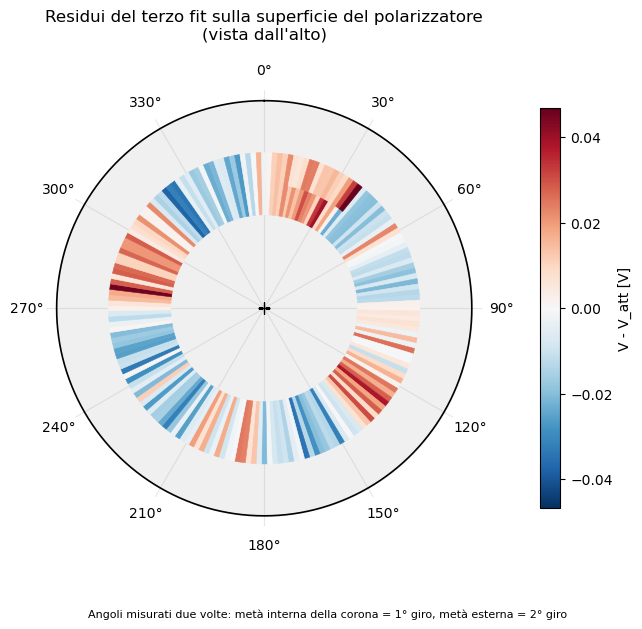

In [306]:

import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# --- parametri modificabili ---------------------------------------------------------------
USA_NORMALIZZATI = False   # False: residui in V | True: residui normalizzati (adimensionali)
R_POL    = 1.0             # raggio del polarizzatore (unità arbitrarie)
R_ANELLO = 0.60            # distanza del centro del fascio dall'asse di rotazione
SPESSORE = 0.30            # diametro del fascio = spessore della corona
ZERO     = "N"             # dove sta lo 0° della scala: "N", "E", "S", "W"
SENSO    = -1              # -1 = la scala cresce in senso orario, +1 = antiorario
# -------------------------------------------------------------------------------------------

val = residuals_3 / err_yeff if USA_NORMALIZZATI else residuals_3

# Posizione sulla superficie = angolo della scala (θ mod 360°), non θ - C:
# è la scala a dire quale punto del polimero sta attraversando il fascio.
gradi = np.round(np.degrees(x), 3)
phi   = np.radians(gradi % 360)
giro  = np.floor(gradi / 360).astype(int)       # 0 = primo giro, 1 = oltre i 360°
dphi  = np.median(np.diff(x))                   # passo angolare (2°)

# Angoli misurati in più giri (es. 26°-38° e 386°-398°): ognuno occupa una fetta radiale della corona
r_in = np.empty_like(phi)
spes = np.empty_like(phi)
for k in np.unique(gradi % 360):
    ii = np.where(gradi % 360 == k)[0]
    ii = ii[np.argsort(giro[ii])]
    for j, i in enumerate(ii):
        spes[i] = SPESSORE / len(ii)
        r_in[i] = R_ANELLO - SPESSORE / 2 + j * SPESSORE / len(ii)

vmax = np.max(np.abs(val))
norm = Normalize(-vmax, vmax)                   # scala simmetrica: bianco = residuo nullo
cmap = plt.cm.RdBu_r                            # rosso = misura sopra il fit, blu = sotto
colori = cmap(norm(val))

fig = plt.figure(figsize=(7.5, 6.5))
ax = fig.add_subplot(111, projection="polar")
ax.set_theta_zero_location(ZERO)
ax.set_theta_direction(SENSO)

t = np.linspace(0, 2*np.pi, 361)
ax.fill_between(t, 0, R_POL, color="0.94", zorder=0)             # superficie del polarizzatore
ax.plot(t, np.full_like(t, R_POL), "k", lw=1.2, zorder=3)        # bordo
ax.plot(0, 0, "k+", ms=8, zorder=3)                              # asse di rotazione
ax.bar(phi, spes, width=dphi, bottom=r_in, color=colori, edgecolor=colori,
       linewidth=0.4, align="center", zorder=2)

ax.set_ylim(0, R_POL * 1.05)
ax.set_rticks([])
ax.spines["polar"].set_visible(False)
ax.set_thetagrids(range(0, 360, 30))
ax.grid(alpha=0.3)
ax.set_title("Residui del terzo fit sulla superficie del polarizzatore\n(vista dall'alto)", pad=18)

sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=ax, pad=0.1, shrink=0.8,
             label="residuo normalizzato" if USA_NORMALIZZATI else "V - V_att [V]")

if np.any(spes < SPESSORE):
    fig.text(0.5, 0.02, "Angoli misurati due volte: metà interna della corona = 1° giro, metà esterna = 2° giro",
             ha="center", fontsize=8)

os.makedirs("Immagini", exist_ok=True)
fig.savefig("Immagini/malus_heatmap_polarizzatore.png", dpi=200, bbox_inches="tight")
plt.show()